In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

print("Project exists:", os.path.exists(PROJECT_DIR))
print("Project path:", PROJECT_DIR)

Project exists: True
Project path: /content/drive/MyDrive/GC210_Retail_Forecasting


In [ ]:
import os

PROCESSED_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting/data/processed"

print("Processed folder exists:", os.path.exists(PROCESSED_DIR))

if os.path.exists(PROCESSED_DIR):
    print("\nFiles currently available:\n")

    for root, dirs, files in os.walk(PROCESSED_DIR):
        level = root.replace(PROCESSED_DIR, "").count(os.sep)
        indent = "    " * level

        print(f"{indent}{os.path.basename(root)}/")

        for file in files:
            print(f"{indent}    {file}")

Processed folder exists: True

Files currently available:

processed/
    m5_development_300_series.parquet
    validation_observations.parquet
    test_observations.parquet
    train_observations.parquet
    validation_targets_28d.parquet
    test_targets_28d.parquet
    training_forecast_origins.parquet
    train_features.parquet
    validation_features.parquet
    test_features.parquet
    supervised_config.json
    supervised/


In [ ]:
DEV_FILE = os.path.join(
    PROCESSED_DIR,
    "m5_development_300_series.parquet"
)

print("Development file exists:", os.path.exists(DEV_FILE))
print("Path:", DEV_FILE)

Development file exists: True
Path: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/m5_development_300_series.parquet


In [ ]:
RAW_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "raw"
)

print("Raw directory exists:", os.path.exists(RAW_DIR))

if os.path.exists(RAW_DIR):

    print("\nRaw files:")

    for file in os.listdir(RAW_DIR):
        print(file)

Raw directory exists: True

Raw files:
calendar.csv
sell_prices.csv
sample_submission.csv
sales_train_validation.csv
sales_train_evaluation.csv


In [ ]:
SALES_FILE = os.path.join(
    RAW_DIR,
    "sales_train_evaluation.csv"
)

CALENDAR_FILE = os.path.join(
    RAW_DIR,
    "calendar.csv"
)

PRICES_FILE = os.path.join(
    RAW_DIR,
    "sell_prices.csv"
)

print(
    "sales_train_evaluation.csv:",
    os.path.exists(SALES_FILE)
)

print(
    "calendar.csv:",
    os.path.exists(CALENDAR_FILE)
)

print(
    "sell_prices.csv:",
    os.path.exists(PRICES_FILE)
)

sales_train_evaluation.csv: True
calendar.csv: True
sell_prices.csv: True


Create the missing supervised directory

In [ ]:
SUPERVISED_DIR = os.path.join(
    PROCESSED_DIR,
    "supervised"
)

os.makedirs(
    SUPERVISED_DIR,
    exist_ok=True
)

print("Created:", SUPERVISED_DIR)
print("Exists:", os.path.exists(SUPERVISED_DIR))

Created: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised
Exists: True


In [ ]:
import pandas as pd
import numpy as np
import json
import os

SEED = 42
HORIZON = 28

np.random.seed(SEED)

sales = pd.read_csv(SALES_FILE)

calendar = pd.read_csv(
    CALENDAR_FILE
)

prices = pd.read_csv(
    PRICES_FILE
)

print("Sales:", sales.shape)
print("Calendar:", calendar.shape)
print("Prices:", prices.shape)

Sales: (30490, 1947)
Calendar: (1969, 14)
Prices: (6841121, 4)


Select the same 300 series

In [ ]:
if os.path.exists(DEV_FILE):

    old_dev = pd.read_parquet(
        DEV_FILE
    )

    selected_ids = (
        old_dev["id"]
        .drop_duplicates()
        .tolist()
    )

    print(
        "Using previous selected IDs:",
        len(selected_ids)
    )

else:

    selected_ids = (
        sales["id"]
        .sample(
            n=300,
            random_state=SEED
        )
        .tolist()
    )

    print(
        "Created new 300-series sample."
    )

Using previous selected IDs: 300


In [ ]:
def normalize_m5_id(x):

    return (
        str(x)
        .replace("_validation", "")
        .replace("_evaluation", "")
    )


sales["series_key"] = (
    sales["id"]
    .apply(normalize_m5_id)
)

selected_keys = [
    normalize_m5_id(x)
    for x in selected_ids
]

sales_300 = sales[
    sales["series_key"].isin(
        selected_keys
    )
].copy()

print(
    "Selected series:",
    sales_300.shape[0]
)

Selected series: 300


Convert wide sales to long format

In [ ]:
id_cols = [
    "id",
    "series_key",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

day_cols = [
    col
    for col in sales_300.columns
    if col.startswith("d_")
]

print(
    "Historical days:",
    len(day_cols)
)

print(
    "Last day:",
    day_cols[-1]
)

Historical days: 1941
Last day: d_1941


In [ ]:
df = sales_300.melt(
    id_vars=id_cols,
    value_vars=day_cols,
    var_name="d",
    value_name="sales"
)

print(df.shape)

display(df.head())

(582300, 9)


,id,series_key,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_100_CA_1_evaluation,HOBBIES_1_100_CA_1,HOBBIES_1_100,HOBBIES_1,HOBBIES,CA_1,CA,d_1,1
1,HOBBIES_1_287_CA_1_evaluation,HOBBIES_1_287_CA_1,HOBBIES_1_287,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_2_008_CA_1_evaluation,HOBBIES_2_008_CA_1,HOBBIES_2_008,HOBBIES_2,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_2_076_CA_1_evaluation,HOBBIES_2_076_CA_1,HOBBIES_2_076,HOBBIES_2,HOBBIES,CA_1,CA,d_1,0
4,HOUSEHOLD_1_176_CA_1_evaluation,HOUSEHOLD_1_176_CA_1,HOUSEHOLD_1_176,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,d_1,0


Merge calendar data

In [ ]:
calendar["date"] = pd.to_datetime(
    calendar["date"]
)

calendar_cols = [
    "d",
    "date",
    "wm_yr_wk",
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

df = df.merge(
    calendar[calendar_cols],
    on="d",
    how="left"
)

print(df.shape)

(582300, 18)


Merge prices

In [ ]:
df = df.merge(
    prices[
        [
            "store_id",
            "item_id",
            "wm_yr_wk",
            "sell_price"
        ]
    ],
    on=[
        "store_id",
        "item_id",
        "wm_yr_wk"
    ],
    how="left"
)

df = df.sort_values(
    ["series_key", "date"]
).reset_index(drop=True)

print(df.shape)

display(
    df[
        [
            "series_key",
            "date",
            "sales",
            "sell_price"
        ]
    ].head()
)

(582300, 19)


,series_key,date,sales,sell_price
0,FOODS_1_005_TX_3,2011-01-29,2,2.94
1,FOODS_1_005_TX_3,2011-01-30,3,2.94
2,FOODS_1_005_TX_3,2011-01-31,3,2.94
3,FOODS_1_005_TX_3,2011-02-01,2,2.94
4,FOODS_1_005_TX_3,2011-02-02,0,2.94


Fix missing price values

In [ ]:
df["sell_price"] = (
    df.groupby("series_key")["sell_price"]
    .transform(
        lambda x: x.ffill().bfill()
    )
)

global_price_median = (
    df["sell_price"].median()
)

df["sell_price"] = (
    df["sell_price"]
    .fillna(global_price_median)
)

print(
    "Remaining missing prices:",
    df["sell_price"].isna().sum()
)

Remaining missing prices: 0


Create leakage-safe demand features

In [ ]:
group = df.groupby(
    "series_key",
    group_keys=False
)

df["lag_1"] = group["sales"].shift(1)
df["lag_7"] = group["sales"].shift(7)
df["lag_14"] = group["sales"].shift(14)
df["lag_28"] = group["sales"].shift(28)

shifted = group["sales"].shift(1)

df["rolling_mean_7"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(7)
    .mean()
    .reset_index(
        level=0,
        drop=True
    )
)

df["rolling_mean_14"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(14)
    .mean()
    .reset_index(
        level=0,
        drop=True
    )
)

df["rolling_mean_28"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(28)
    .mean()
    .reset_index(
        level=0,
        drop=True
    )
)

df["rolling_std_7"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(7)
    .std()
    .reset_index(
        level=0,
        drop=True
    )
)

df["rolling_std_28"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(28)
    .std()
    .reset_index(
        level=0,
        drop=True
    )
)

In [ ]:
shifted = group["sales"].shift(1)

df["rolling_mean_7"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(7)
    .mean()
    .reset_index(
        level=0,
        drop=True
    )
)

df["rolling_mean_14"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(14)
    .mean()
    .reset_index(
        level=0,
        drop=True
    )
)

df["rolling_mean_28"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(28)
    .mean()
    .reset_index(
        level=0,
        drop=True
    )
)

df["rolling_std_7"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(7)
    .std()
    .reset_index(
        level=0,
        drop=True
    )
)

df["rolling_std_28"] = (
    shifted
    .groupby(df["series_key"])
    .rolling(28)
    .std()
    .reset_index(
        level=0,
        drop=True
    )
)

Demand trend feature

In [ ]:
df["demand_ratio_7_28"] = (
    df["rolling_mean_7"]
    /
    (
        df["rolling_mean_28"]
        + 1e-6
    )
)

df["demand_change_7"] = (
    df["lag_1"]
    -
    df["lag_7"]
)

Price features

In [ ]:
df["price_lag_1"] = (
    df.groupby("series_key")[
        "sell_price"
    ].shift(1)
)

df["price_change"] = (
    df["sell_price"]
    -
    df["price_lag_1"]
)

df["price_change_pct"] = (
    df["price_change"]
    /
    (
        df["price_lag_1"]
        + 1e-6
    )
)

shifted_price = (
    df.groupby("series_key")[
        "sell_price"
    ].shift(1)
)

df["price_volatility_7"] = (
    shifted_price
    .groupby(df["series_key"])
    .rolling(7)
    .std()
    .reset_index(
        level=0,
        drop=True
    )
)

Calendar features

In [ ]:
df["day_of_week"] = (
    df["date"].dt.dayofweek
)

df["day_of_month"] = (
    df["date"].dt.day
)

df["week_of_year"] = (
    df["date"]
    .dt.isocalendar()
    .week
    .astype(int)
)

df["month"] = (
    df["date"].dt.month
)

df["quarter"] = (
    df["date"].dt.quarter
)

df["year"] = (
    df["date"].dt.year
)

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

In [ ]:
df["dow_sin"] = np.sin(
    2 * np.pi *
    df["day_of_week"] / 7
)

df["dow_cos"] = np.cos(
    2 * np.pi *
    df["day_of_week"] / 7
)

df["month_sin"] = np.sin(
    2 * np.pi *
    df["month"] / 12
)

df["month_cos"] = np.cos(
    2 * np.pi *
    df["month"] / 12
)

df["week_sin"] = np.sin(
    2 * np.pi *
    df["week_of_year"] / 52
)

df["week_cos"] = np.cos(
    2 * np.pi *
    df["week_of_year"] / 52
)

Event and SNAP features

In [ ]:
for col in [
    "event_name_1",
    "event_name_2",
    "event_type_1",
    "event_type_2"
]:

    df[col] = (
        df[col]
        .fillna("None")
    )

df["has_event_1"] = (
    df["event_name_1"] != "None"
).astype(int)

df["has_event_2"] = (
    df["event_name_2"] != "None"
).astype(int)

df["has_event"] = (
    (
        df["has_event_1"] == 1
    )
    |
    (
        df["has_event_2"] == 1
    )
).astype(int)

df["snap_any"] = (
    (df["snap_CA"] == 1)
    |
    (df["snap_TX"] == 1)
    |
    (df["snap_WI"] == 1)
).astype(int)

Categorical codes

In [ ]:
categorical_columns = [
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

for col in categorical_columns:

    df[f"{col}_code"] = (
        pd.Categorical(
            df[col]
        ).codes
    )

Define the 41 features

In [ ]:
FEATURES = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",

    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",

    "rolling_std_7",
    "rolling_std_28",

    "demand_ratio_7_28",
    "demand_change_7",

    "sell_price",
    "price_change",
    "price_change_pct",
    "price_volatility_7",

    "day_of_week",
    "day_of_month",
    "week_of_year",
    "month",
    "quarter",
    "year",
    "is_weekend",

    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
    "week_sin",
    "week_cos",

    "has_event_1",
    "has_event_2",
    "has_event",

    "snap_CA",
    "snap_TX",
    "snap_WI",
    "snap_any",

    "item_id_code",
    "dept_id_code",
    "cat_id_code",
    "store_id_code",
    "state_id_code"
]

print(
    "Number of features:",
    len(FEATURES)
)

Number of features: 40


Create the 28 future targets

In [ ]:
TARGETS = []

for h in range(
    1,
    HORIZON + 1
):

    target = (
        f"target_day_{h}"
    )

    df[target] = (
        df.groupby(
            "series_key"
        )["sales"]
        .shift(-h)
    )

    TARGETS.append(
        target
    )

print(
    "Targets:",
    len(TARGETS)
)

Targets: 28


Create clean train/validation/test origins

In [ ]:
VALIDATION_ORIGIN = pd.Timestamp(
    "2016-03-27"
)

TEST_ORIGIN = pd.Timestamp(
    "2016-04-24"
)

FIRST_TRAIN_ORIGIN = pd.Timestamp(
    "2011-03-01"
)

LAST_TRAIN_ORIGIN = pd.Timestamp(
    "2016-03-20"
)

In [ ]:
training_origins = pd.date_range(
    start=FIRST_TRAIN_ORIGIN,
    end=LAST_TRAIN_ORIGIN,
    freq="7D"
)

print(
    "Training origins:",
    len(training_origins)
)

print(
    "First:",
    training_origins.min()
)

print(
    "Last:",
    training_origins.max()
)

Training origins: 264
First: 2011-03-01 00:00:00
Last: 2016-03-15 00:00:00


Build the actual supervised datasets

In [ ]:
KEEP_COLUMNS = (
    [
        "id",
        "series_key",
        "date"
    ]
    +
    FEATURES
    +
    TARGETS
)

In [ ]:
train_supervised = df[
    df["date"].isin(
        training_origins
    )
][KEEP_COLUMNS].copy()

In [ ]:
validation_supervised = df[
    df["date"]
    == VALIDATION_ORIGIN
][KEEP_COLUMNS].copy()

In [ ]:
test_supervised = df[
    df["date"]
    == TEST_ORIGIN
][KEEP_COLUMNS].copy()

In [ ]:
train_supervised = (
    train_supervised
    .dropna(
        subset=TARGETS
    )
    .reset_index(drop=True)
)

validation_supervised = (
    validation_supervised
    .dropna(
        subset=TARGETS
    )
    .reset_index(drop=True)
)

test_supervised = (
    test_supervised
    .dropna(
        subset=TARGETS
    )
    .reset_index(drop=True)
)

Do NOT drop series because of missing feature values

In [ ]:
for dataset in [
    train_supervised,
    validation_supervised,
    test_supervised
]:

    dataset[FEATURES] = (
        dataset[FEATURES]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )

In [ ]:
print(
    "Train:",
    train_supervised.shape
)

print(
    "Validation:",
    validation_supervised.shape
)

print(
    "Test:",
    test_supervised.shape
)

print(
    "\nValidation series:",
    validation_supervised[
        "series_key"
    ].nunique()
)

print(
    "Test series:",
    test_supervised[
        "series_key"
    ].nunique()
)

Train: (79200, 71)
Validation: (300, 71)
Test: (300, 71)

Validation series: 300
Test series: 300


Critical date verification

In [ ]:
print("TRAIN")
print(
    train_supervised["date"].min(),
    "→",
    train_supervised["date"].max()
)

print("\nVALIDATION")
print(
    validation_supervised[
        "date"
    ].unique()
)

print("\nTEST")
print(
    test_supervised[
        "date"
    ].unique()
)

TRAIN
2011-03-01 00:00:00 → 2016-03-15 00:00:00

VALIDATION
<DatetimeArray>
['2016-03-27 00:00:00']
Length: 1, dtype: datetime64[ns]

TEST
<DatetimeArray>
['2016-04-24 00:00:00']
Length: 1, dtype: datetime64[ns]


Save the missing files

In [ ]:
os.makedirs(
    SUPERVISED_DIR,
    exist_ok=True
)

TRAIN_OUTPUT = os.path.join(
    SUPERVISED_DIR,
    "train_supervised_28d.parquet"
)

VAL_OUTPUT = os.path.join(
    SUPERVISED_DIR,
    "validation_supervised_28d.parquet"
)

TEST_OUTPUT = os.path.join(
    SUPERVISED_DIR,
    "test_supervised_28d.parquet"
)

CONFIG_OUTPUT = os.path.join(
    SUPERVISED_DIR,
    "supervised_config.json"
)

train_supervised.to_parquet(
    TRAIN_OUTPUT,
    index=False
)

validation_supervised.to_parquet(
    VAL_OUTPUT,
    index=False
)

test_supervised.to_parquet(
    TEST_OUTPUT,
    index=False
)

In [ ]:
config = {
    "horizon": 28,

    "n_features": len(FEATURES),

    "n_targets": len(TARGETS),

    "features": FEATURES,

    "targets": TARGETS,

    "validation_origin":
        str(
            VALIDATION_ORIGIN.date()
        ),

    "test_origin":
        str(
            TEST_ORIGIN.date()
        ),

    "development_series":
        int(
            df["series_key"].nunique()
        ),

    "training_frequency":
        "7D"
}

with open(
    CONFIG_OUTPUT,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=4
    )

print("Files saved.")

Files saved.


Verify that the error is actually fixed

In [ ]:
files_to_check = [
    TRAIN_OUTPUT,
    VAL_OUTPUT,
    TEST_OUTPUT,
    CONFIG_OUTPUT
]

print("=" * 70)
print("STEP 5 FILE VERIFICATION")
print("=" * 70)

for file in files_to_check:

    if os.path.exists(file):

        size_mb = (
            os.path.getsize(file)
            / (1024 ** 2)
        )

        print(
            f"FOUND  -> {file}"
        )

        print(
            f"          Size: "
            f"{size_mb:.2f} MB"
        )

    else:

        print(
            f"MISSING -> {file}"
        )

STEP 5 FILE VERIFICATION
FOUND  -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/train_supervised_28d.parquet
          Size: 1.69 MB
FOUND  -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/validation_supervised_28d.parquet
          Size: 0.06 MB
FOUND  -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/test_supervised_28d.parquet
          Size: 0.06 MB
FOUND  -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/supervised_config.json
          Size: 0.00 MB


Final sanity check

In [ ]:
check_train = pd.read_parquet(
    TRAIN_OUTPUT
)

check_val = pd.read_parquet(
    VAL_OUTPUT
)

check_test = pd.read_parquet(
    TEST_OUTPUT
)

with open(
    CONFIG_OUTPUT,
    "r"
) as f:

    check_config = json.load(f)

print("=" * 60)
print("STEP 5 REPAIR SUCCESSFUL")
print("=" * 60)

print(
    "Train:",
    check_train.shape
)

print(
    "Validation:",
    check_val.shape
)

print(
    "Test:",
    check_test.shape
)

print(
    "Features:",
    len(
        check_config["features"]
    )
)

print(
    "Targets:",
    len(
        check_config["targets"]
    )
)

print(
    "Validation series:",
    check_val[
        "series_key"
    ].nunique()
)

print(
    "Test series:",
    check_test[
        "series_key"
    ].nunique()
)

STEP 5 REPAIR SUCCESSFUL
Train: (79200, 71)
Validation: (300, 71)
Test: (300, 71)
Features: 40
Targets: 28
Validation series: 300
Test series: 300


Load the Step 5 datasets

In [ ]:
import os
import json
import joblib
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# -------------------------------------------------------
# Basic settings
# -------------------------------------------------------
SEED = 42
HORIZON = 28

random.seed(SEED)
np.random.seed(SEED)

# -------------------------------------------------------
# Project paths
# -------------------------------------------------------
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed"
)

SUPERVISED_DIR = os.path.join(
    PROCESSED_DIR,
    "supervised"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

PREDICTIONS_DIR = os.path.join(
    RESULTS_DIR,
    "predictions"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

for folder in [
    MODEL_DIR,
    RESULTS_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    FIGURES_DIR
]:
    os.makedirs(folder, exist_ok=True)

# -------------------------------------------------------
# File paths
# -------------------------------------------------------
train_path = os.path.join(
    SUPERVISED_DIR,
    "train_supervised_28d.parquet"
)

val_path = os.path.join(
    SUPERVISED_DIR,
    "validation_supervised_28d.parquet"
)

test_path = os.path.join(
    SUPERVISED_DIR,
    "test_supervised_28d.parquet"
)

config_path = os.path.join(
    SUPERVISED_DIR,
    "supervised_config.json"
)

# -------------------------------------------------------
# Load data
# -------------------------------------------------------
train_df = pd.read_parquet(train_path)
val_df = pd.read_parquet(val_path)
test_df = pd.read_parquet(test_path)

print("=" * 60)
print("DATA LOADED SUCCESSFULLY")
print("=" * 60)

print("Training shape   :", train_df.shape)
print("Validation shape :", val_df.shape)
print("Test shape       :", test_df.shape)

display(train_df.head())

DATA LOADED SUCCESSFULLY
Training shape   : (79200, 71)
Validation shape : (300, 71)
Test shape       : (300, 71)


,id,series_key,date,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28,...,target_day_19,target_day_20,target_day_21,target_day_22,target_day_23,target_day_24,target_day_25,target_day_26,target_day_27,target_day_28
0,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,2011-03-01,1.0,0.0,2.0,2.0,0.857143,1.000000,1.571429,...,1.0,2.0,1.0,2.0,1.0,0.0,0.0,3.0,2.0,1.0
1,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,2011-03-08,2.0,0.0,0.0,2.0,1.000000,0.928571,1.357143,...,3.0,2.0,1.0,0.0,2.0,2.0,0.0,1.0,0.0,0.0
2,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,2011-03-15,0.0,2.0,0.0,2.0,1.428571,1.214286,1.107143,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0
3,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,2011-03-22,2.0,1.0,2.0,0.0,2.000000,1.714286,1.321429,...,0.0,2.0,0.0,3.0,1.0,3.0,0.0,2.0,0.0,2.0
4,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,2011-03-29,2.0,1.0,1.0,0.0,1.285714,1.642857,1.428571,...,2.0,0.0,2.0,3.0,4.0,5.0,5.0,6.0,7.0,2.0


Load the feature configuration

In [ ]:
with open(config_path, "r") as f:
    config = json.load(f)

FEATURES = config["features"]
TARGETS = config["targets"]

HORIZON = len(TARGETS)

print("=" * 60)
print("CONFIGURATION")
print("=" * 60)

print("Number of features :", len(FEATURES))
print("Number of targets  :", len(TARGETS))
print("Forecast horizon   :", HORIZON)

print("\nFeatures:")
for i, feature in enumerate(FEATURES, 1):
    print(f"{i:02d}. {feature}")

print("\nTargets:")
print(TARGETS)

CONFIGURATION
Number of features : 40
Number of targets  : 28
Forecast horizon   : 28

Features:
01. lag_1
02. lag_7
03. lag_14
04. lag_28
05. rolling_mean_7
06. rolling_mean_14
07. rolling_mean_28
08. rolling_std_7
09. rolling_std_28
10. demand_ratio_7_28
11. demand_change_7
12. sell_price
13. price_change
14. price_change_pct
15. price_volatility_7
16. day_of_week
17. day_of_month
18. week_of_year
19. month
20. quarter
21. year
22. is_weekend
23. dow_sin
24. dow_cos
25. month_sin
26. month_cos
27. week_sin
28. week_cos
29. has_event_1
30. has_event_2
31. has_event
32. snap_CA
33. snap_TX
34. snap_WI
35. snap_any
36. item_id_code
37. dept_id_code
38. cat_id_code
39. store_id_code
40. state_id_code

Targets:
['target_day_1', 'target_day_2', 'target_day_3', 'target_day_4', 'target_day_5', 'target_day_6', 'target_day_7', 'target_day_8', 'target_day_9', 'target_day_10', 'target_day_11', 'target_day_12', 'target_day_13', 'target_day_14', 'target_day_15', 'target_day_16', 'target_day_17', '

Validate all required columns

In [ ]:
def check_required_columns(
    dataset,
    dataset_name,
    features,
    targets
):
    required = features + targets

    missing = [
        col
        for col in required
        if col not in dataset.columns
    ]

    if missing:
        print(
            f"ERROR: {dataset_name} is missing "
            f"{len(missing)} columns:"
        )
        print(missing)

        return False

    print(
        f"{dataset_name}: all required columns found."
    )

    return True


train_ok = check_required_columns(
    train_df,
    "TRAIN",
    FEATURES,
    TARGETS
)

val_ok = check_required_columns(
    val_df,
    "VALIDATION",
    FEATURES,
    TARGETS
)

test_ok = check_required_columns(
    test_df,
    "TEST",
    FEATURES,
    TARGETS
)

if not all([
    train_ok,
    val_ok,
    test_ok
]):
    raise ValueError(
        "Required columns are missing. "
        "Check Step 5."
    )

print("\nColumn verification successful.")

TRAIN: all required columns found.
VALIDATION: all required columns found.
TEST: all required columns found.

Column verification successful.


Convert everything to numeric safely

In [ ]:
for col in FEATURES + TARGETS:

    train_df[col] = pd.to_numeric(
        train_df[col],
        errors="coerce"
    )

    val_df[col] = pd.to_numeric(
        val_df[col],
        errors="coerce"
    )

    test_df[col] = pd.to_numeric(
        test_df[col],
        errors="coerce"
    )

print("Numeric conversion completed.")

Numeric conversion completed.


In [ ]:
for dataset in [
    train_df,
    val_df,
    test_df
]:

    dataset[FEATURES] = (
        dataset[FEATURES]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )

print("Infinite values converted to NaN.")

Infinite values converted to NaN.


Handle missing feature values

In [ ]:
train_feature_medians = (
    train_df[FEATURES]
    .median()
)

# If any feature is entirely missing,
# replace its median with zero.
train_feature_medians = (
    train_feature_medians
    .fillna(0)
)

train_df[FEATURES] = (
    train_df[FEATURES]
    .fillna(
        train_feature_medians
    )
)

val_df[FEATURES] = (
    val_df[FEATURES]
    .fillna(
        train_feature_medians
    )
)

test_df[FEATURES] = (
    test_df[FEATURES]
    .fillna(
        train_feature_medians
    )
)

In [ ]:
print(
    "Before target cleaning:"
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

train_df = (
    train_df
    .dropna(
        subset=TARGETS
    )
    .reset_index(drop=True)
)

val_df = (
    val_df
    .dropna(
        subset=TARGETS
    )
    .reset_index(drop=True)
)

test_df = (
    test_df
    .dropna(
        subset=TARGETS
    )
    .reset_index(drop=True)
)

print(
    "\nAfter target cleaning:"
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Before target cleaning:
Train: (79200, 71)
Validation: (300, 71)
Test: (300, 71)

After target cleaning:
Train: (79200, 71)
Validation: (300, 71)
Test: (300, 71)


Final missing-value check

In [ ]:
print("=" * 60)
print("MISSING VALUE CHECK")
print("=" * 60)

print(
    "Train feature NaN:",
    train_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

print(
    "Validation feature NaN:",
    val_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

print(
    "Test feature NaN:",
    test_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

print()

print(
    "Train target NaN:",
    train_df[TARGETS]
    .isna()
    .sum()
    .sum()
)

print(
    "Validation target NaN:",
    val_df[TARGETS]
    .isna()
    .sum()
    .sum()
)

print(
    "Test target NaN:",
    test_df[TARGETS]
    .isna()
    .sum()
    .sum()
)

MISSING VALUE CHECK
Train feature NaN: 0
Validation feature NaN: 0
Test feature NaN: 0

Train target NaN: 0
Validation target NaN: 0
Test target NaN: 0


Create X and y arrays

In [ ]:
X_train = train_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

y_train = train_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

X_val = val_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

y_val = val_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

X_test = test_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

y_test = test_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

print("=" * 60)
print("MODEL ARRAYS")
print("=" * 60)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

MODEL ARRAYS
X_train: (79200, 40)
y_train: (79200, 28)
X_val: (300, 40)
y_val: (300, 28)
X_test: (300, 40)
y_test: (300, 28)


Check for NaN/infinity

In [ ]:
arrays = {
    "X_train": X_train,
    "y_train": y_train,
    "X_val": X_val,
    "y_val": y_val,
    "X_test": X_test,
    "y_test": y_test
}

all_valid = True

for name, array in arrays.items():

    valid = np.isfinite(
        array
    ).all()

    print(
        f"{name:10s}:",
        "OK" if valid else "INVALID"
    )

    if not valid:
        all_valid = False

if not all_valid:
    raise ValueError(
        "NaN or infinity detected."
    )

print(
    "\nAll model arrays are valid."
)

X_train   : OK
y_train   : OK
X_val     : OK
y_val     : OK
X_test    : OK
y_test    : OK

All model arrays are valid.


Evaluation metrics

In [ ]:
def calculate_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    # Demand cannot be negative
    y_pred = np.clip(
        y_pred,
        0,
        None
    )

    # -------------------------
    # MAE
    # -------------------------
    mae = np.mean(
        np.abs(
            y_true - y_pred
        )
    )

    # -------------------------
    # RMSE
    # -------------------------
    rmse = np.sqrt(
        np.mean(
            (
                y_true -
                y_pred
            ) ** 2
        )
    )

    # -------------------------
    # WAPE
    # -------------------------
    denominator = np.sum(
        np.abs(y_true)
    )

    if denominator > 0:

        wape = (
            np.sum(
                np.abs(
                    y_true -
                    y_pred
                )
            )
            /
            denominator
        ) * 100

    else:

        wape = np.nan

    # -------------------------
    # sMAPE
    # -------------------------
    smape_denominator = (
        np.abs(y_true)
        +
        np.abs(y_pred)
    )

    smape_numerator = (
        2 *
        np.abs(
            y_true -
            y_pred
        )
    )

    smape_array = np.divide(
        smape_numerator,
        smape_denominator,
        out=np.zeros_like(
            smape_numerator,
            dtype=np.float64
        ),
        where=(
            smape_denominator != 0
        )
    )

    smape = (
        np.mean(
            smape_array
        ) * 100
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "WAPE": float(wape),
        "sMAPE": float(smape)
    }

In [ ]:
def evaluate_model(
    model_name,
    y_true,
    y_pred
):

    metrics = calculate_metrics(
        y_true,
        y_pred
    )

    result = {
        "Model": model_name
    }

    result.update(
        metrics
    )

    return result

Seasonal Naive baseline

In [ ]:
required_naive_features = [
    "lag_7",
    "lag_14",
    "lag_28"
]

for feature in required_naive_features:

    if feature not in FEATURES:

        raise ValueError(
            f"{feature} not found "
            "in FEATURES."
        )

lag7_idx = FEATURES.index(
    "lag_7"
)

lag14_idx = FEATURES.index(
    "lag_14"
)

lag28_idx = FEATURES.index(
    "lag_28"
)

print("lag_7 index :", lag7_idx)
print("lag_14 index:", lag14_idx)
print("lag_28 index:", lag28_idx)

lag_7 index : 1
lag_14 index: 2
lag_28 index: 3


In [ ]:
def create_seasonal_naive(
    X
):

    n = X.shape[0]

    predictions = np.zeros(
        (
            n,
            HORIZON
        ),
        dtype=np.float32
    )

    lag7 = X[:, lag7_idx]
    lag14 = X[:, lag14_idx]
    lag28 = X[:, lag28_idx]

    # Forecast days 1-7
    predictions[:, 0:7] = (
        lag7[:, None]
    )

    # Forecast days 8-14
    predictions[:, 7:14] = (
        lag14[:, None]
    )

    # Forecast days 15-28
    predictions[:, 14:28] = (
        lag28[:, None]
    )

    predictions = np.clip(
        predictions,
        0,
        None
    )

    return predictions

In [ ]:
val_pred_naive = (
    create_seasonal_naive(
        X_val
    )
)

test_pred_naive = (
    create_seasonal_naive(
        X_test
    )
)

print(
    "Validation:",
    val_pred_naive.shape
)

print(
    "Test:",
    test_pred_naive.shape
)

Validation: (300, 28)
Test: (300, 28)


In [ ]:
naive_val_metrics = (
    evaluate_model(
        "Seasonal Naive",
        y_val,
        val_pred_naive
    )
)

naive_test_metrics = (
    evaluate_model(
        "Seasonal Naive",
        y_test,
        test_pred_naive
    )
)

print(
    "VALIDATION:"
)

print(
    naive_val_metrics
)

print(
    "\nTEST:"
)

print(
    naive_test_metrics
)

VALIDATION:
{'Model': 'Seasonal Naive', 'MAE': 1.213690476190476, 'RMSE': 2.3378103308132467, 'WAPE': 103.03183425972713, 'sMAPE': 82.73733962369101}

TEST:
{'Model': 'Seasonal Naive', 'MAE': 1.2554761904761904, 'RMSE': 2.874394346143698, 'WAPE': 105.81978727674093, 'sMAPE': 86.52897178662307}


Standardize features for MLP and later Autoencoders

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = (
    scaler
    .fit_transform(
        X_train
    )
    .astype(np.float32)
)

X_val_scaled = (
    scaler
    .transform(
        X_val
    )
    .astype(np.float32)
)

X_test_scaled = (
    scaler
    .transform(
        X_test
    )
    .astype(np.float32)
)

print(
    "Scaled train:",
    X_train_scaled.shape
)

print(
    "Scaled validation:",
    X_val_scaled.shape
)

print(
    "Scaled test:",
    X_test_scaled.shape
)

Scaled train: (79200, 40)
Scaled validation: (300, 40)
Scaled test: (300, 40)


In [ ]:
print(
    "Training mean:",
    np.mean(
        X_train_scaled
    )
)

print(
    "Training std:",
    np.std(
        X_train_scaled
    )
)

print(
    "Finite:",
    np.isfinite(
        X_train_scaled
    ).all()
)

Training mean: 4.8936015e-09
Training std: 0.90829533
Finite: True


In [ ]:
scaler_path = os.path.join(
    MODEL_DIR,
    "neural_feature_scaler.pkl"
)

joblib.dump(
    scaler,
    scaler_path
)

print(
    "Scaler saved successfully."
)

Scaler saved successfully.


Import TensorFlow

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

tf.random.set_seed(SEED)

print(
    "TensorFlow:",
    tf.__version__
)

print(
    "GPU devices:",
    tf.config.list_physical_devices(
        "GPU"
    )
)

TensorFlow: 2.20.0
GPU devices: []


Build the MLP baseline

In [ ]:
tf.keras.backend.clear_session()

mlp_model = Sequential([

    Input(
        shape=(
            len(FEATURES),
        )
    ),

    Dense(
        128,
        activation="relu"
    ),

    BatchNormalization(),

    Dropout(
        0.20
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(
        0.10
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        HORIZON,
        activation="linear"
    )
])

mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 28)             │           924 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,020 (66.48 KB)

 Trainable params: 16,764 (65.48 KB)

 Non-trainable params: 256 (1.00 KB)

Compile MLP

In [ ]:
mlp_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mae",

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        )
    ]
)

print(
    "MLP compiled successfully."
)

MLP compiled successfully.


Define callbacks

In [ ]:
early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=8,

    restore_best_weights=True,

    verbose=1
)


reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=4,

    min_lr=1e-6,

    verbose=1
)

print("Callbacks ready.")

Callbacks ready.


Train MLP

In [ ]:
history = mlp_model.fit(

    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=60,

    batch_size=256,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 0.7235 - mae: 0.7235 - val_loss: 0.8623 - val_mae: 0.8623 - learning_rate: 0.0010
Epoch 2/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.6644 - mae: 0.6644 - val_loss: 0.8643 - val_mae: 0.8643 - learning_rate: 0.0010
Epoch 3/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.6608 - mae: 0.6608 - val_loss: 0.8685 - val_mae: 0.8685 - learning_rate: 0.0010
Epoch 4/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.6576 - mae: 0.6576 - val_loss: 0.8643 - val_mae: 0.8643 - learning_rate: 0.0010
Epoch 5/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.6559 - mae: 0.6559 - val_loss: 0.8620 - val_mae: 0.8620 - learning_rate: 0.0010
Epoch 6/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.6555 - mae: 0.6555 - val_loss: 0.8615 - val_mae: 0.8615 - learning_rate: 0.0010
Epoch 7/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.6542 - mae: 0.6542 - val_loss: 0.8627 - val_mae: 0.8627 - learning_rate: 0.0010
Epoch

MLP predictions

In [ ]:
val_pred_mlp = (
    mlp_model.predict(
        X_val_scaled,
        batch_size=256,
        verbose=0
    )
)

test_pred_mlp = (
    mlp_model.predict(
        X_test_scaled,
        batch_size=256,
        verbose=0
    )
)

val_pred_mlp = np.clip(
    val_pred_mlp,
    0,
    None
)

test_pred_mlp = np.clip(
    test_pred_mlp,
    0,
    None
)

print(
    "Validation predictions:",
    val_pred_mlp.shape
)

print(
    "Test predictions:",
    test_pred_mlp.shape
)

Validation predictions: (300, 28)
Test predictions: (300, 28)


Evaluate MLP

In [ ]:
mlp_val_metrics = (
    evaluate_model(
        "MLP",
        y_val,
        val_pred_mlp
    )
)

mlp_test_metrics = (
    evaluate_model(
        "MLP",
        y_test,
        test_pred_mlp
    )
)

print("=" * 60)
print("MLP RESULTS")
print("=" * 60)

print(
    "\nValidation:"
)

for key, value in (
    mlp_val_metrics.items()
):

    print(
        key,
        ":",
        value
    )

print(
    "\nTest:"
)

for key, value in (
    mlp_test_metrics.items()
):

    print(
        key,
        ":",
        value
    )

MLP RESULTS

Validation:
Model : MLP
MAE : 0.8611165616739076
RMSE : 1.7753151152832598
WAPE : 73.10135541243885
sMAPE : 147.57489815847813

Test:
Model : MLP
MAE : 0.9003482354622087
RMSE : 1.8434702193694708
WAPE : 75.8872684916973
sMAPE : 151.5954645040076


Save MLP model

In [ ]:
mlp_model_path = os.path.join(
    MODEL_DIR,
    "mlp_baseline.keras"
)

mlp_model.save(
    mlp_model_path
)

print(
    "MLP model saved:"
)

print(
    mlp_model_path
)

MLP model saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/models/mlp_baseline.keras


Plot MLP training history

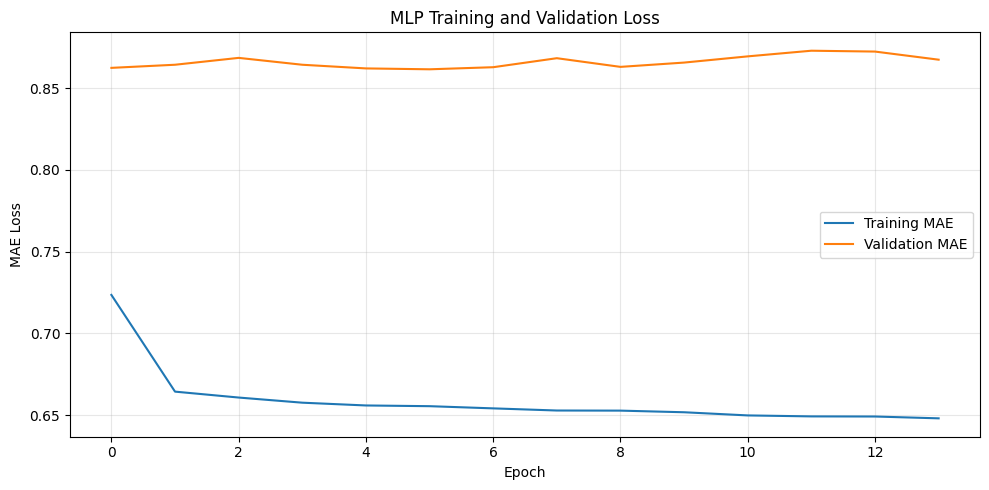

Figure saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/figures/mlp_training_history.png


In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history.history["loss"],
    label="Training MAE"
)

plt.plot(
    history.history["val_loss"],
    label="Validation MAE"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MAE Loss"
)

plt.title(
    "MLP Training and Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

mlp_figure_path = os.path.join(
    FIGURES_DIR,
    "mlp_training_history.png"
)

plt.savefig(
    mlp_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved:",
    mlp_figure_path
)

Install/import LightGBM

In [ ]:
!pip install -q lightgbm

In [ ]:
from lightgbm import LGBMRegressor

print(
    "LightGBM imported successfully."
)

LightGBM imported successfully.


In [ ]:
from lightgbm import LGBMRegressor

print(
    "LightGBM imported successfully."
)

Initialize LightGBM predictions

In [ ]:
lightgbm_models = []

val_pred_lgbm = np.zeros(
    (
        X_val.shape[0],
        HORIZON
    ),
    dtype=np.float32
)

test_pred_lgbm = np.zeros(
    (
        X_test.shape[0],
        HORIZON
    ),
    dtype=np.float32
)

print(
    "LightGBM containers initialized."
)

LightGBM containers initialized.


Train 28 LightGBM models

In [ ]:
for h in range(HORIZON):

    print(
        f"Training forecast day "
        f"{h + 1:02d}/{HORIZON}"
    )

    model = LGBMRegressor(

        objective="regression_l1",

        n_estimators=300,

        learning_rate=0.05,

        num_leaves=31,

        max_depth=-1,

        min_child_samples=20,

        colsample_bytree=0.8,

        reg_alpha=0.1,

        reg_lambda=0.1,

        random_state=SEED,

        n_jobs=-1,

        verbosity=-1
    )

    model.fit(
        X_train,
        y_train[:, h]
    )

    val_pred_lgbm[:, h] = (
        model.predict(
            X_val
        )
    )

    test_pred_lgbm[:, h] = (
        model.predict(
            X_test
        )
    )

    lightgbm_models.append(
        model
    )

print(
    "\nAll 28 LightGBM models "
    "trained successfully."
)

Training forecast day 01/28
Training forecast day 02/28
Training forecast day 03/28
Training forecast day 04/28
Training forecast day 05/28
Training forecast day 06/28
Training forecast day 07/28
Training forecast day 08/28
Training forecast day 09/28
Training forecast day 10/28
Training forecast day 11/28
Training forecast day 12/28
Training forecast day 13/28
Training forecast day 14/28
Training forecast day 15/28
Training forecast day 16/28
Training forecast day 17/28
Training forecast day 18/28
Training forecast day 19/28
Training forecast day 20/28
Training forecast day 21/28
Training forecast day 22/28
Training forecast day 23/28
Training forecast day 24/28
Training forecast day 25/28
Training forecast day 26/28
Training forecast day 27/28
Training forecast day 28/28

All 28 LightGBM models trained successfully.


Clean LightGBM predictions

In [ ]:
for h in range(HORIZON):

    print(
        f"Training forecast day "
        f"{h + 1:02d}/{HORIZON}"
    )

    model = LGBMRegressor(

        objective="regression_l1",

        n_estimators=300,

        learning_rate=0.05,

        num_leaves=31,

        max_depth=-1,

        min_child_samples=20,

        colsample_bytree=0.8,

        reg_alpha=0.1,

        reg_lambda=0.1,

        random_state=SEED,

        n_jobs=-1,

        verbosity=-1
    )

    model.fit(
        X_train,
        y_train[:, h]
    )

    val_pred_lgbm[:, h] = (
        model.predict(
            X_val
        )
    )

    test_pred_lgbm[:, h] = (
        model.predict(
            X_test
        )
    )

    lightgbm_models.append(
        model
    )

print(
    "\nAll 28 LightGBM models "
    "trained successfully."
)

Training forecast day 01/28
Training forecast day 02/28
Training forecast day 03/28
Training forecast day 04/28
Training forecast day 05/28
Training forecast day 06/28
Training forecast day 07/28
Training forecast day 08/28
Training forecast day 09/28
Training forecast day 10/28
Training forecast day 11/28
Training forecast day 12/28
Training forecast day 13/28
Training forecast day 14/28
Training forecast day 15/28
Training forecast day 16/28
Training forecast day 17/28
Training forecast day 18/28
Training forecast day 19/28
Training forecast day 20/28
Training forecast day 21/28
Training forecast day 22/28
Training forecast day 23/28
Training forecast day 24/28
Training forecast day 25/28
Training forecast day 26/28
Training forecast day 27/28
Training forecast day 28/28

All 28 LightGBM models trained successfully.


Evaluate LightGBM

In [ ]:
lgbm_val_metrics = (
    evaluate_model(
        "LightGBM",
        y_val,
        val_pred_lgbm
    )
)

lgbm_test_metrics = (
    evaluate_model(
        "LightGBM",
        y_test,
        test_pred_lgbm
    )
)

print("=" * 60)
print("LIGHTGBM RESULTS")
print("=" * 60)

print("\nValidation:")

for key, value in (
    lgbm_val_metrics.items()
):
    print(
        key,
        ":",
        value
    )

print("\nTest:")

for key, value in (
    lgbm_test_metrics.items()
):
    print(
        key,
        ":",
        value
    )

LIGHTGBM RESULTS

Validation:
Model : LightGBM
MAE : 0.8331928763833664
RMSE : 1.7977139481300064
WAPE : 70.7308758122312
sMAPE : 100.80823942319101

Test:
Model : LightGBM
MAE : 0.8468848167427032
RMSE : 1.8053968421797815
WAPE : 71.38102007464084
sMAPE : 102.49820513047321


Save LightGBM models

In [ ]:
lgbm_model_path = os.path.join(
    MODEL_DIR,
    "lightgbm_28_models.pkl"
)

joblib.dump(
    lightgbm_models,
    lgbm_model_path
)

print(
    "LightGBM models saved:"
)

print(
    lgbm_model_path
)

LightGBM models saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/models/lightgbm_28_models.pkl


Compare all baseline models

In [ ]:
validation_results = pd.DataFrame([
    naive_val_metrics,
    mlp_val_metrics,
    lgbm_val_metrics
])

test_results = pd.DataFrame([
    naive_test_metrics,
    mlp_test_metrics,
    lgbm_test_metrics
])

print("=" * 70)
print("VALIDATION RESULTS")
print("=" * 70)

display(
    validation_results.round(4)
)

print("\n")

print("=" * 70)
print("TEST RESULTS")
print("=" * 70)

display(
    test_results.round(4)
)

VALIDATION RESULTS


,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2137,2.3378,103.0318,82.7373
1,MLP,0.8611,1.7753,73.1014,147.5749
2,LightGBM,0.8332,1.7977,70.7309,100.8082




TEST RESULTS


,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982


Save metrics

In [ ]:
validation_metrics_path = os.path.join(
    METRICS_DIR,
    "baseline_validation_metrics.csv"
)

test_metrics_path = os.path.join(
    METRICS_DIR,
    "baseline_test_metrics.csv"
)

validation_results.to_csv(
    validation_metrics_path,
    index=False
)

test_results.to_csv(
    test_metrics_path,
    index=False
)

print(
    "Validation metrics saved:"
)

print(
    validation_metrics_path
)

print(
    "\nTest metrics saved:"
)

print(
    test_metrics_path
)

Validation metrics saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/baseline_validation_metrics.csv

Test metrics saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/baseline_test_metrics.csv


Create prediction-saving function

In [ ]:
def create_prediction_dataframe(
    source_df,
    y_true,
    y_pred,
    model_name
):

    records = []

    # Prefer series_key
    if "series_key" in source_df.columns:

        series_ids = (
            source_df[
                "series_key"
            ].astype(str).values
        )

    else:

        series_ids = (
            source_df[
                "id"
            ].astype(str).values
        )

    for i in range(
        len(series_ids)
    ):

        for h in range(
            HORIZON
        ):

            records.append({
                "series_id":
                    series_ids[i],

                "forecast_day":
                    h + 1,

                "actual":
                    float(
                        y_true[i, h]
                    ),

                "prediction":
                    float(
                        y_pred[i, h]
                    ),

                "model":
                    model_name
            })

    return pd.DataFrame(
        records
    )

Save baseline predictions

In [ ]:
naive_predictions = (
    create_prediction_dataframe(
        test_df,
        y_test,
        test_pred_naive,
        "Seasonal Naive"
    )
)

naive_predictions.to_csv(
    os.path.join(
        PREDICTIONS_DIR,
        "seasonal_naive_test_predictions.csv"
    ),
    index=False
)

In [ ]:
mlp_predictions = (
    create_prediction_dataframe(
        test_df,
        y_test,
        test_pred_mlp,
        "MLP"
    )
)

mlp_predictions.to_csv(
    os.path.join(
        PREDICTIONS_DIR,
        "mlp_test_predictions.csv"
    ),
    index=False
)

In [ ]:
lgbm_predictions = (
    create_prediction_dataframe(
        test_df,
        y_test,
        test_pred_lgbm,
        "LightGBM"
    )
)

lgbm_predictions.to_csv(
    os.path.join(
        PREDICTIONS_DIR,
        "lightgbm_test_predictions.csv"
    ),
    index=False
)

print(
    "All baseline predictions saved."
)

All baseline predictions saved.


Forecast horizon analysis

In [ ]:
def calculate_horizon_mae(
    y_true,
    y_pred
):

    return np.mean(
        np.abs(
            y_true -
            y_pred
        ),
        axis=0
    )

In [ ]:
naive_horizon_mae = (
    calculate_horizon_mae(
        y_test,
        test_pred_naive
    )
)

mlp_horizon_mae = (
    calculate_horizon_mae(
        y_test,
        test_pred_mlp
    )
)

lgbm_horizon_mae = (
    calculate_horizon_mae(
        y_test,
        test_pred_lgbm
    )
)

horizon_results = pd.DataFrame({

    "Forecast_Day":
        np.arange(
            1,
            HORIZON + 1
        ),

    "Seasonal_Naive_MAE":
        naive_horizon_mae,

    "MLP_MAE":
        mlp_horizon_mae,

    "LightGBM_MAE":
        lgbm_horizon_mae
})

display(
    horizon_results.head(28)
)

,Forecast_Day,Seasonal_Naive_MAE,MLP_MAE,LightGBM_MAE
0,1,1.170000,0.743757,0.744949
1,2,1.253333,0.792893,0.765046
2,3,1.270000,0.793759,0.734357
3,4,1.276667,0.845910,0.798561
4,5,1.183333,0.788431,0.780929
5,6,1.136667,0.908851,0.863786
6,7,1.216667,1.085212,0.984945
7,8,1.180000,0.818236,0.774028
8,9,1.220000,0.866642,0.827927
9,10,1.306667,0.747563,0.678389


In [ ]:
horizon_results.to_csv(
    os.path.join(
        METRICS_DIR,
        "baseline_horizon_mae.csv"
    ),
    index=False
)

Plot 28-day horizon performance

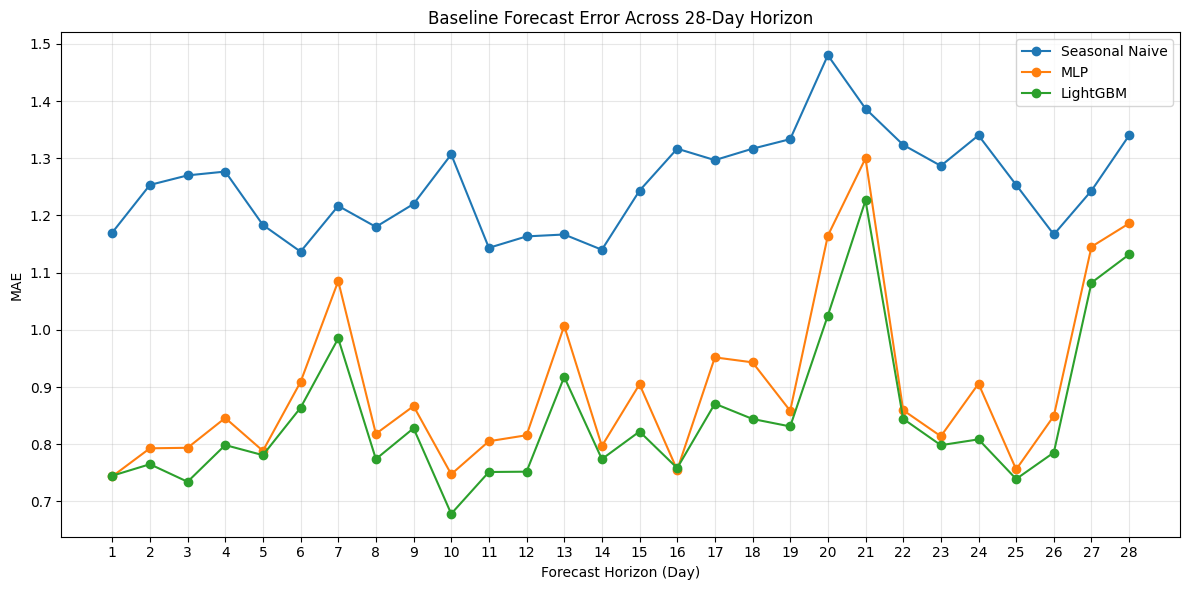

In [ ]:
days = np.arange(
    1,
    HORIZON + 1
)

plt.figure(
    figsize=(12, 6)
)

plt.plot(
    days,
    naive_horizon_mae,
    marker="o",
    label="Seasonal Naive"
)

plt.plot(
    days,
    mlp_horizon_mae,
    marker="o",
    label="MLP"
)

plt.plot(
    days,
    lgbm_horizon_mae,
    marker="o",
    label="LightGBM"
)

plt.xlabel(
    "Forecast Horizon (Day)"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "Baseline Forecast Error Across 28-Day Horizon"
)

plt.xticks(
    np.arange(
        1,
        29
    )
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

horizon_plot_path = os.path.join(
    FIGURES_DIR,
    "baseline_horizon_mae.png"
)

plt.savefig(
    horizon_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

LightGBM feature importance

In [ ]:
importance_matrix = np.array([
    model.feature_importances_
    for model in lightgbm_models
])

average_importance = (
    importance_matrix.mean(
        axis=0
    )
)

importance_df = pd.DataFrame({

    "Feature":
        FEATURES,

    "Importance":
        average_importance
})

importance_df = (
    importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

display(
    importance_df.head(20)
)

,Feature,Importance
0,rolling_mean_28,1714.571429
1,rolling_std_28,1063.321429
2,demand_ratio_7_28,788.285714
3,rolling_mean_7,727.035714
4,rolling_mean_14,709.571429
5,item_id_code,698.142857
6,sell_price,569.500000
7,rolling_std_7,490.464286
8,day_of_month,404.142857
9,year,239.428571


LightGBM feature importance

In [ ]:
importance_matrix = np.array([
    model.feature_importances_
    for model in lightgbm_models
])

average_importance = (
    importance_matrix.mean(
        axis=0
    )
)

importance_df = pd.DataFrame({

    "Feature":
        FEATURES,

    "Importance":
        average_importance
})

importance_df = (
    importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

display(
    importance_df.head(20)
)

In [ ]:
importance_path = os.path.join(
    METRICS_DIR,
    "lightgbm_feature_importance.csv"
)

importance_df.to_csv(
    importance_path,
    index=False
)

print(
    "Feature importance saved."
)

Feature importance saved.


Plot top 20 features

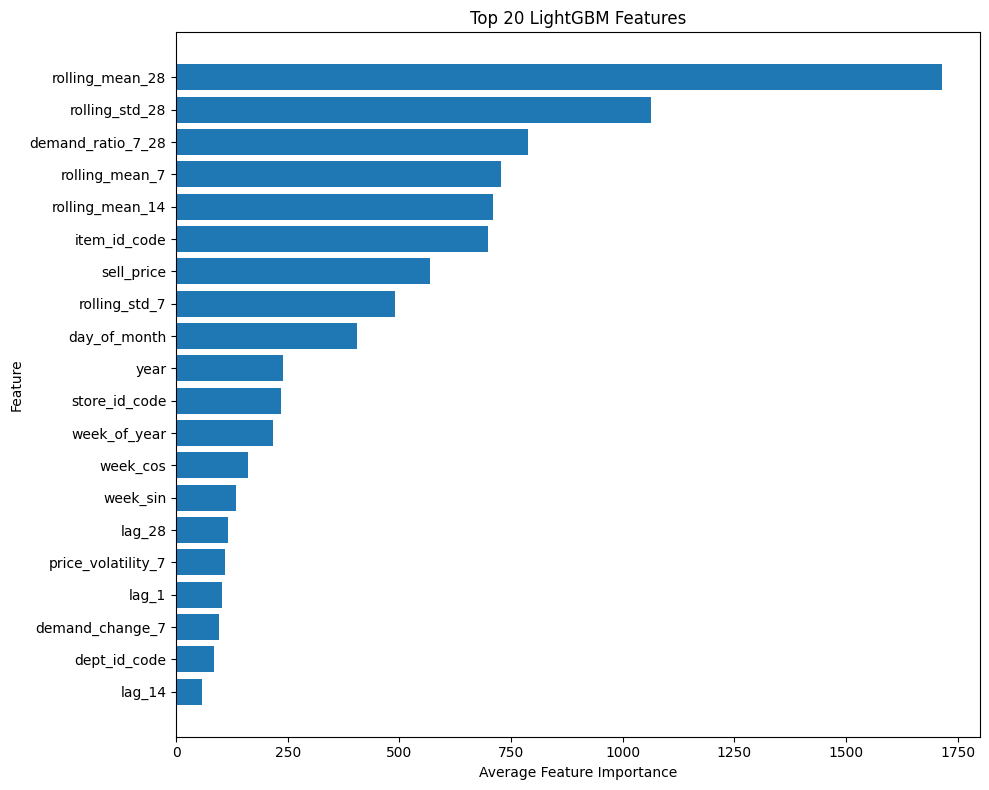

In [ ]:
top20 = (
    importance_df
    .head(20)
    .sort_values(
        "Importance"
    )
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.xlabel(
    "Average Feature Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Top 20 LightGBM Features"
)

plt.tight_layout()

importance_plot_path = os.path.join(
    FIGURES_DIR,
    "lightgbm_feature_importance.png"
)

plt.savefig(
    importance_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Actual vs predicted example

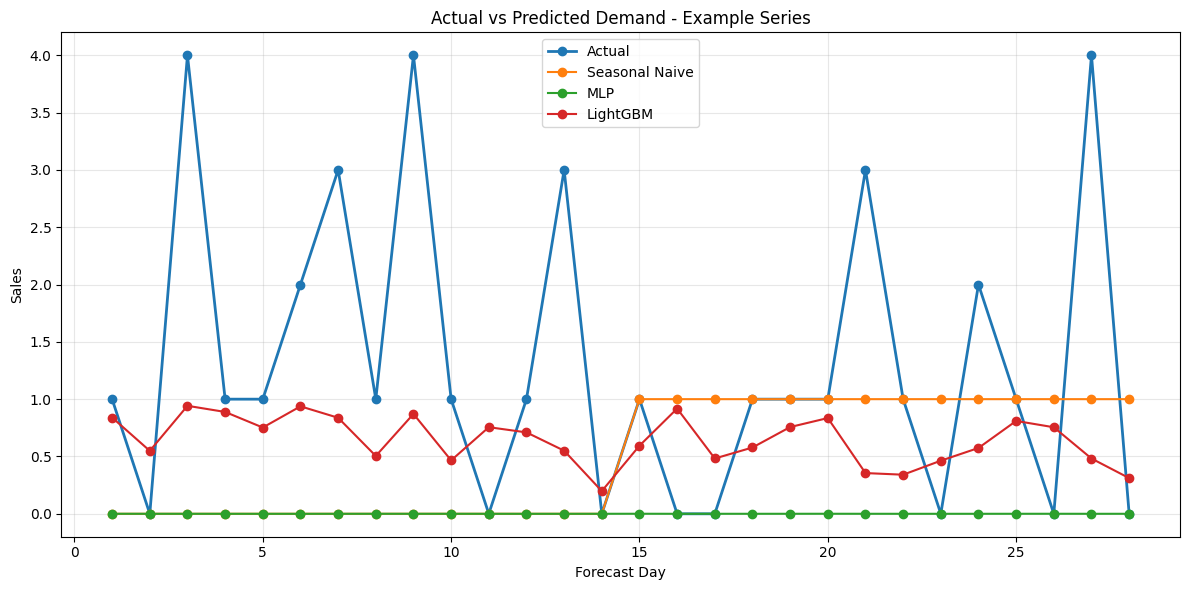

In [ ]:
SERIES_INDEX = 0

days = np.arange(
    1,
    HORIZON + 1
)

plt.figure(
    figsize=(12, 6)
)

plt.plot(
    days,
    y_test[SERIES_INDEX],
    marker="o",
    linewidth=2,
    label="Actual"
)

plt.plot(
    days,
    test_pred_naive[SERIES_INDEX],
    marker="o",
    label="Seasonal Naive"
)

plt.plot(
    days,
    test_pred_mlp[SERIES_INDEX],
    marker="o",
    label="MLP"
)

plt.plot(
    days,
    test_pred_lgbm[SERIES_INDEX],
    marker="o",
    label="LightGBM"
)

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "Sales"
)

plt.title(
    "Actual vs Predicted Demand - Example Series"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

Final automatic verification

In [ ]:
print("=" * 70)
print("STEP 6 FINAL VERIFICATION")
print("=" * 70)

print("\n1. DATA")
print("-" * 30)

print(
    "Train      :",
    X_train.shape,
    y_train.shape
)

print(
    "Validation :",
    X_val.shape,
    y_val.shape
)

print(
    "Test       :",
    X_test.shape,
    y_test.shape
)

print("\n2. MODEL CONFIGURATION")
print("-" * 30)

print(
    "Input features :",
    len(FEATURES)
)

print(
    "Forecast days  :",
    HORIZON
)

print("\n3. PREDICTION SHAPES")
print("-" * 30)

print(
    "Naive:",
    test_pred_naive.shape
)

print(
    "MLP:",
    test_pred_mlp.shape
)

print(
    "LightGBM:",
    test_pred_lgbm.shape
)

print("\n4. VALIDATION RESULTS")
print("-" * 30)

display(
    validation_results.round(4)
)

print("\n5. TEST RESULTS")
print("-" * 30)

display(
    test_results.round(4)
)

print("\n6. SAVED MODELS")
print("-" * 30)

print(
    "Scaler:",
    os.path.exists(
        scaler_path
    )
)

print(
    "MLP:",
    os.path.exists(
        mlp_model_path
    )
)

print(
    "LightGBM:",
    os.path.exists(
        lgbm_model_path
    )
)

print("\n7. SAVED RESULTS")
print("-" * 30)

print(
    "Validation metrics:",
    os.path.exists(
        validation_metrics_path
    )
)

print(
    "Test metrics:",
    os.path.exists(
        test_metrics_path
    )
)

print("\n" + "=" * 70)

if (
    os.path.exists(mlp_model_path)
    and
    os.path.exists(lgbm_model_path)
    and
    os.path.exists(test_metrics_path)
):

    print(
        "STEP 6 COMPLETED SUCCESSFULLY"
    )

else:

    print(
        "STEP 6 INCOMPLETE - "
        "CHECK OUTPUT ABOVE"
    )

print("=" * 70)

STEP 6 FINAL VERIFICATION

1. DATA
------------------------------
Train      : (79200, 40) (79200, 28)
Validation : (300, 40) (300, 28)
Test       : (300, 40) (300, 28)

2. MODEL CONFIGURATION
------------------------------
Input features : 40
Forecast days  : 28

3. PREDICTION SHAPES
------------------------------
Naive: (300, 28)
MLP: (300, 28)
LightGBM: (300, 28)

4. VALIDATION RESULTS
------------------------------


,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2137,2.3378,103.0318,82.7373
1,MLP,0.8611,1.7753,73.1014,147.5749
2,LightGBM,0.8332,1.7977,70.7309,100.8082



5. TEST RESULTS
------------------------------


,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982



6. SAVED MODELS
------------------------------
Scaler: True
MLP: True
LightGBM: True

7. SAVED RESULTS
------------------------------
Validation metrics: True
Test metrics: True

STEP 6 COMPLETED SUCCESSFULLY
